--- 5 Baris Pertama Data US Arrests ---
            Murder  Assault  UrbanPop  Rape
State                                      
Alabama       13.2      236        58  21.2
Alaska        10.0      263        48  44.5
Arizona        8.1      294        80  31.0
Arkansas       8.8      190        50  19.5
California     9.0      276        91  40.6


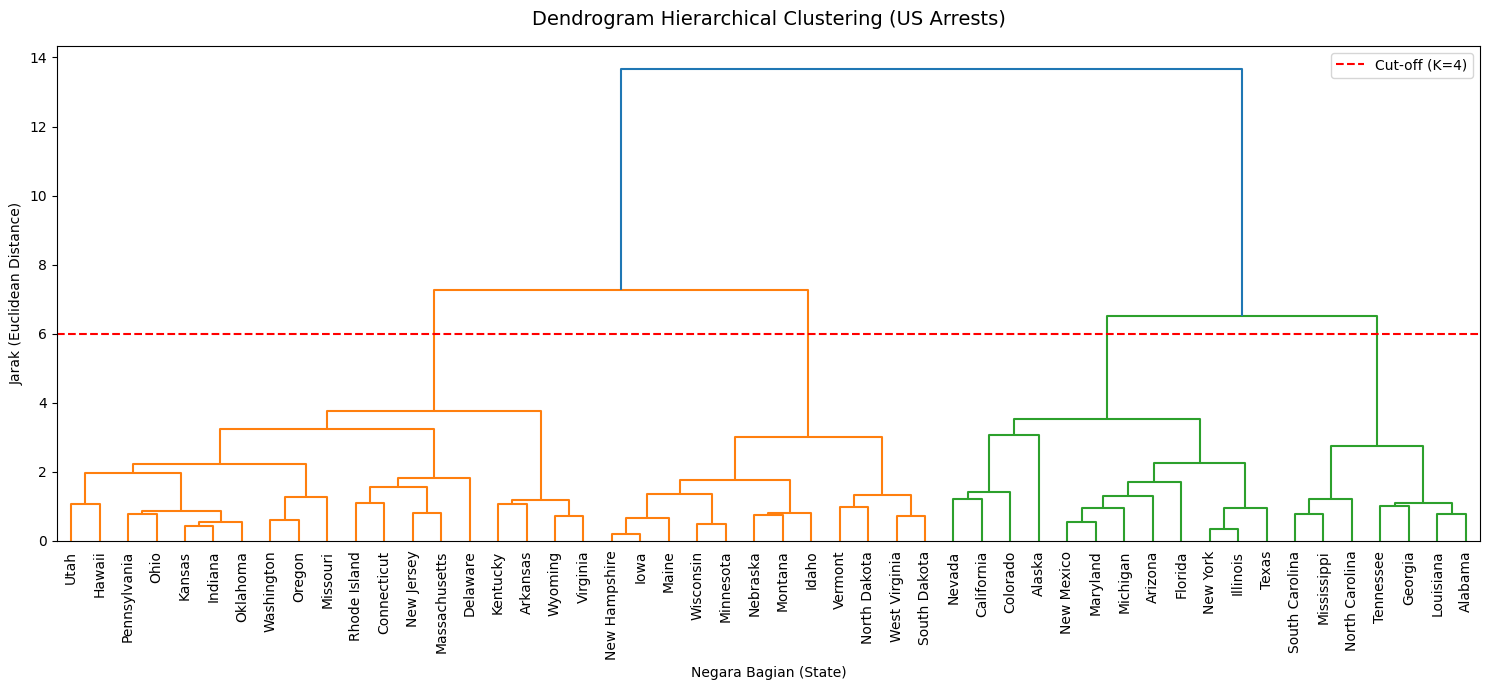


--- Hasil Evaluasi ---
Silhouette Score (K=4): 0.3370

--- Rata-rata Fitur per Cluster ---
            Murder     Assault   UrbanPop       Rape
Cluster                                             
0         6.210526  142.052632  71.263158  19.184211
1        10.966667  264.000000  76.500000  33.608333
2         3.091667   76.000000  52.083333  11.833333
3        14.671429  251.285714  54.285714  21.685714


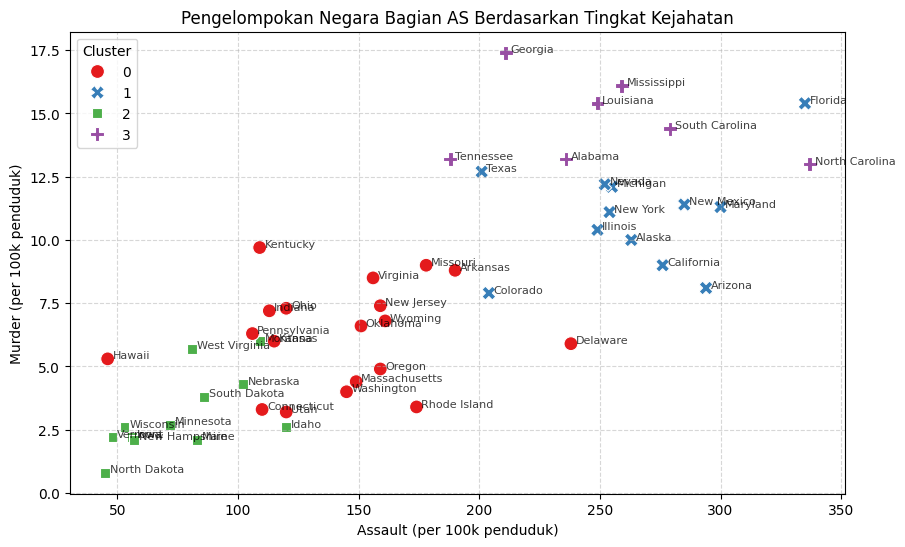

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

# 1. READ DATASET (Gunakan index_col=0 agar kolom pertama otomatis jadi Index/State)
url = "https://raw.githubusercontent.com/vincentarelbundock/Rdatasets/master/csv/datasets/USArrests.csv"
df = pd.read_csv(url, index_col=0)

# Opsional: Jika kolom indeks tidak punya nama, beri nama 'State' untuk kerapian
df.index.name = "State"

print("--- 5 Baris Pertama Data US Arrests ---")
print(df.head())


# 2. PREPROCESSING DATA
X = df.copy()

# Scaling fitur (sangat penting karena rentang Assault jauh lebih besar dari Murder)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)


# 3. VISUALISASI DENDROGRAM DENGAN NAMA STATE
linked = linkage(X_scaled, method="ward")

plt.figure(figsize=(15, 7))
dendrogram(
    linked,
    orientation="top",
    labels=df.index.tolist(),  # Nama negara bagian diambil dari Index dataframe
    distance_sort="descending",
    show_leaf_counts=True,
    leaf_rotation=90,
    leaf_font_size=10,
)
plt.title("Dendrogram Hierarchical Clustering (US Arrests)", fontsize=14, pad=15)
plt.xlabel("Negara Bagian (State)")
plt.ylabel("Jarak (Euclidean Distance)")

# Garis potong (threshold cut-off) untuk memotong menjadi 4 cluster
plt.axhline(y=6, color="r", linestyle="--", label="Cut-off (K=4)")
plt.legend()
plt.tight_layout()
plt.show()


# 4. TRAINING MODEL AGGLOMERATIVE CLUSTERING
n_clusters = 4
model = AgglomerativeClustering(
    n_clusters=n_clusters, metric="euclidean", linkage="ward"
)
df["Cluster"] = model.fit_predict(X_scaled)


# 5. EVALUASI MODEL
sil_score = silhouette_score(X_scaled, df["Cluster"])
print(f"\n--- Hasil Evaluasi ---")
print(f"Silhouette Score (K={n_clusters}): {sil_score:.4f}")


# 6. RATA-RATA FITUR PER CLUSTER
print("\n--- Rata-rata Fitur per Cluster ---")
print(df.groupby("Cluster").mean())


# 7. VISUALISASI SCATTER PLOT (Murder vs Assault)
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df,
    x="Assault",
    y="Murder",
    hue="Cluster",
    palette="Set1",
    s=100,
    style="Cluster",
)

# Label teks nama State pada titik scatter plot
for state in df.index:
    plt.text(
        df.loc[state, "Assault"] + 2,
        df.loc[state, "Murder"],
        state,
        fontsize=8,
        alpha=0.75,
    )

plt.title("Pengelompokan Negara Bagian AS Berdasarkan Tingkat Kejahatan")
plt.xlabel("Assault (per 100k penduduk)")
plt.ylabel("Murder (per 100k penduduk)")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()